<a href="https://colab.research.google.com/github/bofdada/BOFDADA.GITHUB.IO/blob/main/mRNA_Raut.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

In [ ]:
# Set the random seed so everyone receives the same results
np.random.seed(42)

number_of_samples = 500

data = pd.DataFrame({
    "mrna_dose": np.random.uniform(10, 100, number_of_samples),
    "storage_temperature": np.random.uniform(-80, 8, number_of_samples),
    "mrna_stability": np.random.uniform(0.40, 1.00, number_of_samples),
    "delivery_efficiency": np.random.uniform(0.30, 1.00, number_of_samples),
    "participant_age": np.random.randint(18, 81, number_of_samples),
    "days_since_vaccination": np.random.randint(7, 61, number_of_samples)
})

# Create a fictional immune-response score
response_score = (
    0.03 * data["mrna_dose"]
    + 3.0 * data["mrna_stability"]
    + 4.0 * data["delivery_efficiency"]
    - 0.02 * data["participant_age"]
    + 0.01 * data["days_since_vaccination"]
    + np.random.normal(0, 1, number_of_samples)
)

# Convert the score into two categories
data["strong_immune_response"] = (
    response_score > np.median(response_score)
).astype(int)

data.head()

,mrna_dose,storage_temperature,mrna_stability,delivery_efficiency,participant_age,days_since_vaccination,strong_immune_response
0,43.708611,-18.561769,0.511080,0.663357,45,7,0
1,95.564288,-32.823520,0.725141,0.635427,24,14,1
2,75.879455,-52.761570,0.923768,0.317949,52,51,1
3,63.879264,-8.386038,0.839335,0.538873,72,29,0
4,24.041678,-19.743657,0.883937,0.566137,45,53,0


In [ ]:
print("Dataset shape:", data.shape)
print()

print("First five rows:")
display(data.head())

print("Summary statistics:")
display(data.describe())

print("Immune response counts:")
print(data["strong_immune_response"].value_counts())

Dataset shape: (500, 7)

First five rows:


,mrna_dose,storage_temperature,mrna_stability,delivery_efficiency,participant_age,days_since_vaccination,strong_immune_response
0,43.708611,-18.561769,0.511080,0.663357,45,7,0
1,95.564288,-32.823520,0.725141,0.635427,24,14,1
2,75.879455,-52.761570,0.923768,0.317949,52,51,1
3,63.879264,-8.386038,0.839335,0.538873,72,29,0
4,24.041678,-19.743657,0.883937,0.566137,45,53,0


Summary statistics:


,mrna_dose,storage_temperature,mrna_stability,delivery_efficiency,participant_age,days_since_vaccination,strong_immune_response
count,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000
mean,54.870554,-37.588277,0.710535,0.647534,49.488000,34.520000,0.500000
std,26.881957,25.123424,0.178316,0.200907,18.485163,15.801423,0.500501
min,10.455543,-79.592382,0.402964,0.302253,18.000000,7.000000,0.000000
25%,31.715172,-59.839266,0.544737,0.468752,34.000000,21.000000,0.000000
50%,56.184737,-38.479702,0.723843,0.656224,50.000000,35.000000,0.500000
75%,78.051239,-16.082360,0.866406,0.816163,66.000000,48.250000,1.000000
max,99.366832,7.975155,0.999648,0.998843,80.000000,60.000000,1.000000


Immune response counts:
strong_immune_response
0    250
1    250
Name: count, dtype: int64


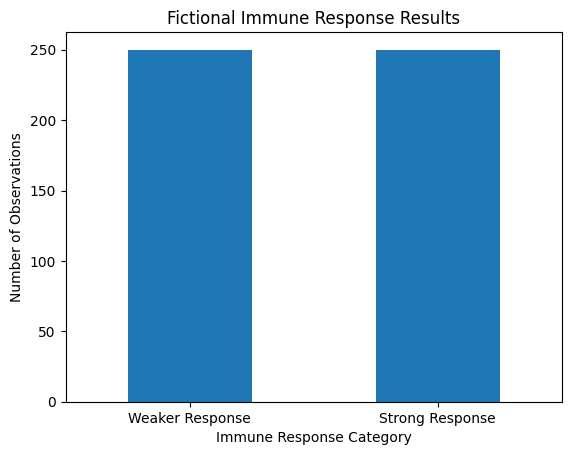

In [ ]:
response_counts = data["strong_immune_response"].value_counts().sort_index()

response_counts.plot(kind="bar")

plt.title("Fictional Immune Response Results")
plt.xlabel("Immune Response Category")
plt.ylabel("Number of Observations")
plt.xticks([0, 1], ["Weaker Response", "Strong Response"], rotation=0)
plt.show()

In [ ]:
X = data.drop("strong_immune_response", axis=1)
y = data["strong_immune_response"]

print("Features:")
print(list(X.columns))

print("\nLabel:")
print(y.name)

Features:
['mrna_dose', 'storage_temperature', 'mrna_stability', 'delivery_efficiency', 'participant_age', 'days_since_vaccination']

Label:
strong_immune_response


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training observations:", len(X_train))
print("Testing observations:", len(X_test))

Training observations: 400
Testing observations: 100


In [ ]:
X = data.drop("strong_immune_response", axis=1)
y = data["strong_immune_response"]

print("Features:")
print(list(X.columns))

print("\nLabel:")
print(y.name)

Features:
['mrna_dose', 'storage_temperature', 'mrna_stability', 'delivery_efficiency', 'participant_age', 'days_since_vaccination']

Label:
strong_immune_response


In [ ]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [ ]:
model = Sequential([
    Dense(12, activation="relu", input_shape=(X_train_scaled.shape[1],)),
    Dense(6, activation="relu"),
    Dense(1, activation="sigmoid")
])

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 12)             │            84 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │            78 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │             7 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 169 (676.00 B)

 Trainable params: 169 (676.00 B)

 Non-trainable params: 0 (0.00 B)

In [ ]:
history = model.fit(
    X_train_scaled,
    y_train,
    epochs=30,
    batch_size=16,
    validation_split=0.20,
    verbose=0
)

print("Training complete.")

Training complete.


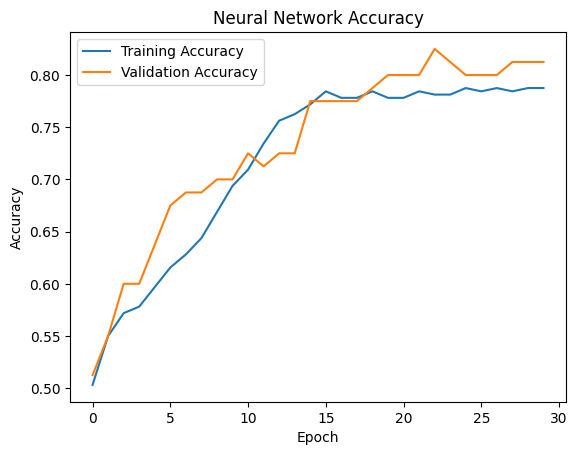

In [ ]:
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.title("Neural Network Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

In [ ]:
test_loss, test_accuracy = model.evaluate(
    X_test_scaled,
    y_test,
    verbose=0
)

print(f"Testing accuracy: {test_accuracy:.2%}")

Testing accuracy: 79.00%


Prediction accuracy: 79.00%


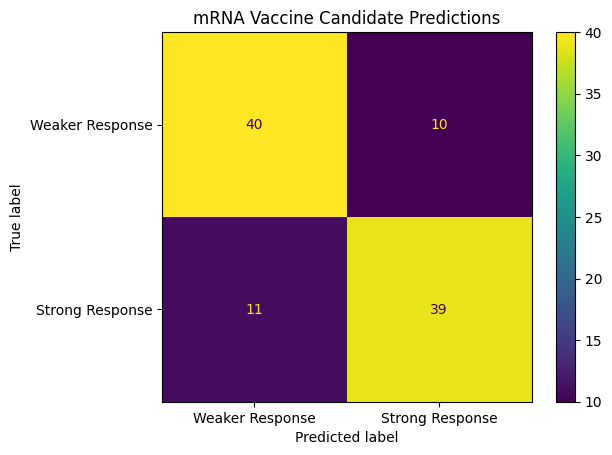

In [ ]:
prediction_probabilities = model.predict(
    X_test_scaled,
    verbose=0
)

predictions = (
    prediction_probabilities >= 0.50
).astype(int).flatten()

accuracy = accuracy_score(y_test, predictions)

print(f"Prediction accuracy: {accuracy:.2%}")

ConfusionMatrixDisplay.from_predictions(
    y_test,
    predictions,
    display_labels=["Weaker Response", "Strong Response"]
)

plt.title("mRNA Vaccine Candidate Predictions")
plt.show()

In [ ]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [ ]:
new_candidate = pd.DataFrame({
    "mrna_dose": [75],
    "storage_temperature": [-40],
    "mrna_stability": [0.88],
    "delivery_efficiency": [0.85],
    "participant_age": [40],
    "days_since_vaccination": [28]
})

new_candidate_scaled = scaler.transform(new_candidate)

predicted_probability = model.predict(
    new_candidate_scaled,
    verbose=0
)[0][0]

print(
    f"Predicted probability of a strong immune response: "
    f"{predicted_probability:.2%}"
)

if predicted_probability >= 0.50:
    print("Model prediction: Strong immune response")
else:
    print("Model prediction: Weaker immune response")

Predicted probability of a strong immune response: 96.16%
Model prediction: Strong immune response


In [ ]:
new_candidate = pd.DataFrame({
    "mrna_dose": [100],
    "storage_temperature": [-40],
    "mrna_stability": [0.88],
    "delivery_efficiency": [0.95],
    "participant_age": [40],
    "days_since_vaccination": [28]
})

new_candidate_scaled = scaler.transform(new_candidate)

predicted_probability = model.predict(
    new_candidate_scaled,
    verbose=0
)[0][0]

print(f"Predicted probability: {predicted_probability:.2%}")
if predicted_probability >= 0.50:
    print("Model prediction: Strong immune response")
else:
    print("Model prediction: Weaker immune response")

Predicted probability: 99.06%
Model prediction: Strong immune response
